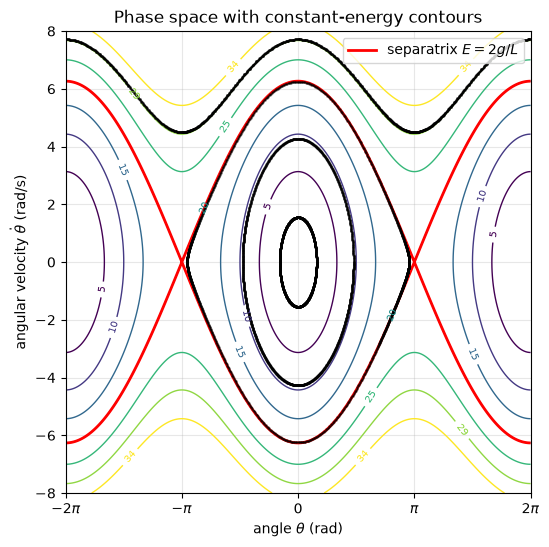

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
 
g, L = 9.81, 1.0                 # gravity (m/s^2), pendulum length (m)
w0_sq = g / L                    # natural frequency squared
E_sep = 2 * w0_sq                # separatrix energy per unit m*L^2: E = w^2/2 + (g/L)(1 - cos th)
 
 
def energy(theta, omega):
    """Energy per unit (m L^2): kinetic + potential."""
    return 0.5 * omega**2 + w0_sq * (1 - np.cos(theta))
 
 
def trajectory(theta0, omega0=0.0, t_max=10.0, n=2000):
    """Integrate the full nonlinear pendulum equation  theta'' = -(g/L) sin(theta)."""
    rhs = lambda t, y: [y[1], -w0_sq * np.sin(y[0])]
    t = np.linspace(0, t_max, n)
    sol = solve_ivp(rhs, (0, t_max), [theta0, omega0], t_eval=t, rtol=1e-10, atol=1e-10)
    return sol.y[0], sol.y[1]
 
 
fig, ax1 = plt.subplots(1, 1, figsize=(6, 6))
 
th = np.linspace(-2 * np.pi, 2 * np.pi, 800)
om = np.linspace(-8, 8, 800)
TH, OM = np.meshgrid(th, om)
E = energy(TH, OM)
 
levels = np.linspace(0.5, 3.5, 7) * w0_sq
cs = ax1.contour(TH, OM, E, levels=levels, cmap="viridis", linewidths=1)
ax1.clabel(cs, fmt=lambda v: f"{v:.0f}", fontsize=7)
ax1.contour(TH, OM, E, levels=[E_sep], colors="red", linewidths=2)   # separatrix
 
# Overlay a few simulated trajectories (oscillation, near-separatrix, rotation)
for th0, w0 in [(0.5, 0), (1.5, 0), (3.0, 0), (-np.pi, 4.5)]:
    x, y = trajectory(th0, w0, t_max=6)
    x = (x + 2 * np.pi) % (4 * np.pi) - 2 * np.pi if abs(w0) > 0 else x
    ax1.plot(x, y, ".", ms=1.5, color="k", alpha=0.5)
 
ax1.plot([], [], color="red", lw=2, label=r"separatrix $E = 2g/L$")
ax1.set_xlim(-2 * np.pi, 2 * np.pi)
ax1.set_ylim(-8, 8)
ax1.set_xticks(np.arange(-2, 3) * np.pi)
ax1.set_xticklabels([r"$-2\pi$", r"$-\pi$", "0", r"$\pi$", r"$2\pi$"])
ax1.set_xlabel(r"angle $\theta$ (rad)")
ax1.set_ylabel(r"angular velocity $\dot\theta$ (rad/s)")
ax1.set_title("Phase space with constant-energy contours")
ax1.legend(loc="upper right")
ax1.grid(alpha=0.3)
